# DSP Laboratory — Lab 1A: Sampling, Aliasing and Quantization

**Student Details:**
* **Name:** ALAN GURUMEL ENOCK
* **Registration Number:** 240242417475
* **Group:** 6
* **Class:** BENG24Coe 1
* **GitHub:** [Allan-Davincs](https://github.com/Allan-Davincs/)

## Pre-Lab Preparation

### **Question (a)**
A 7 kHz tone is sampled at 10 kHz. What frequency appears?

* **Answer:**
  Using the aliasing relation:
  $$f_{\text{alias}} = |f_0 - k \cdot f_s|$$
  Here, $f_0 = 7\text{ kHz}$ and $f_s = 10\text{ kHz}$.
  With $k = 1$:
  $$f_{\text{alias}} = |7 - 10| = 3\text{ kHz}$$
  The frequency that appears is **$3\text{ kHz}$**.

---

### **Question (b)**
Compute $\Delta$ and the theoretical SQNR for an 8-bit quantizer with a $\pm1\text{ V}$ range.

* **Answer:**
  * Full scale range $2 X_m = 2\text{ V}$
  * Step size:
    $$\Delta = \frac{2 X_m}{2^B} = \frac{2}{256} = 0.0078125\text{ V} = 7.81\text{ mV}$$
  * Theoretical SQNR:
    $$\text{SQNR} = 6.02 B + 1.76 = 6.02(8) + 1.76 = 49.92\text{ dB}$$
  The step size is **$7.81\text{ mV}$** and the theoretical SQNR is **$49.92\text{ dB}$**.

## Setup and Imports

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
import pandas as pd
import os

# Consistent figure layout
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

## Task 2.1 — Aliasing of a sinusoid

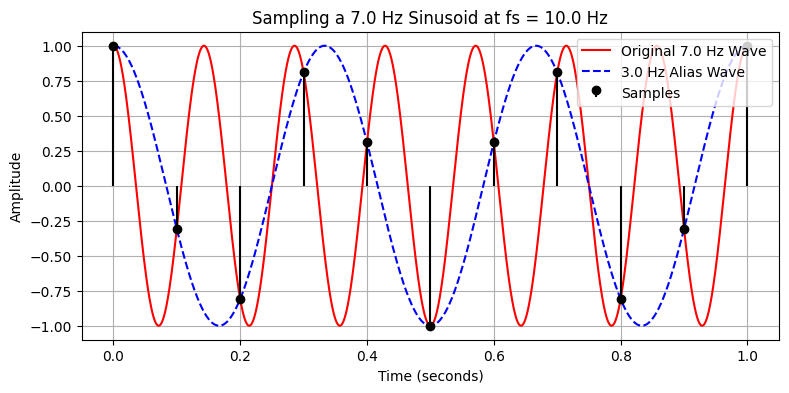

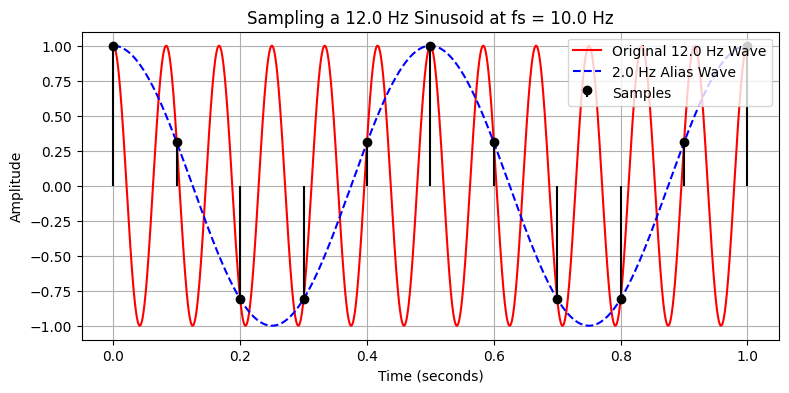

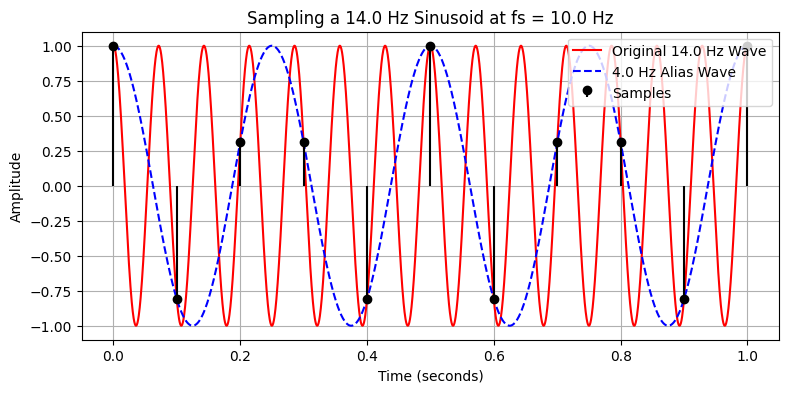

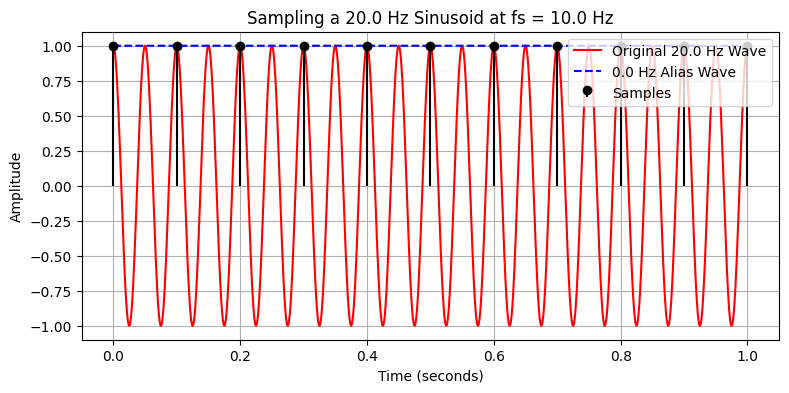

In [6]:
def plot_aliasing(f0, fs=10.0):
    # Dense grid representing continuous analog signal
    t = np.linspace(0, 1, 2000)
    # Discrete sampling time points
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Analytical alias calculation
    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.figure()
    # Plot "analog" original continuous signal
    plt.plot(t, np.cos(2 * np.pi * f0 * t), 'r-', label=f"Original {f0} Hz Wave")
    # Plot "analog" reconstructed/alias wave
    plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--", color='blue', label=f"{f_alias} Hz Alias Wave")
    # Plot discrete sample points
    plt.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="Samples")

    plt.title(f"Sampling a {f0} Hz Sinusoid at fs = {fs} Hz")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.legend(loc="upper right")
    plt.show()

    return f_alias

# Run the simulation for the requested frequencies
f0_list = [7.0, 12.0, 14.0, 20.0]
alias_results = []
for f0 in f0_list:
    alias_val = plot_aliasing(f0, fs=10.0)
    alias_results.append({"Original F_0 (Hz)": f0, "Calculated Alias F_alias (Hz)": alias_val})

### **Alias Frequency Summary Table**

In [7]:
df_alias = pd.DataFrame(alias_results)
df_alias

,Original F_0 (Hz),Calculated Alias F_alias (Hz)
0,7.0,3.0
1,12.0,2.0
2,14.0,4.0
3,20.0,0.0


## Task 2.2 — Hear aliasing

In [8]:
# Load recording or generate continuous-time fallback chirp signal
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print(f"Loaded voice file: {fname} at {fs} Hz")
else:
    # Fallback: a professional chirp sweep from 200 Hz to 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print("Fallback chirp signal generated (44.1 kHz sampling rate).")

# Downsample with and without low-pass filtering
for k in [2, 4, 8]:
    naive = x[::k] # Decimation without filter (aliasing occurs)
    proper = signal.decimate(x, k, ftype="fir") # Low-pass anti-aliasing filter applied, then downsample
    print(f"Factor k = {k}: New Sampling Frequency = {fs // k} Hz")

Fallback chirp signal generated (44.1 kHz sampling rate).
Factor k = 2: New Sampling Frequency = 22050 Hz
Factor k = 4: New Sampling Frequency = 11025 Hz
Factor k = 8: New Sampling Frequency = 5512 Hz


### Interactive Sound Generation and Audition ($k = 8$)

In [9]:
k_factor = 8
new_fs = fs // k_factor
naive_signal = x[::k_factor]
proper_signal = signal.decimate(x, k_factor, ftype="fir")

print("Naïve downsampling (Aliased - High frequency noise gets folded down):")
display(Audio(naive_signal, rate=new_fs))

print("Proper downsampling (Anti-aliased - Clean but low-pass filtered sound):")
display(Audio(proper_signal, rate=new_fs))

Naïve downsampling (Aliased - High frequency noise gets folded down):


Proper downsampling (Anti-aliased - Clean but low-pass filtered sound):


### **Observations for $k = 8$**
* **Decimation without pre-filtering (Naïve):** The signal exhibits severe frequency foldback (aliasing). For instance, the sweep direction is reversed at times, and voice recordings sound metallic or highly distorted.
* **Decimation with pre-filtering (Proper):** Lowpass filtering removes high-frequency components above the new Nyquist limit ($2756\text{ Hz}$) before downsampling, giving a clean but slightly muffled output with no alias artifacts.

## Task 2.3 — Uniform Quantizer Implementation

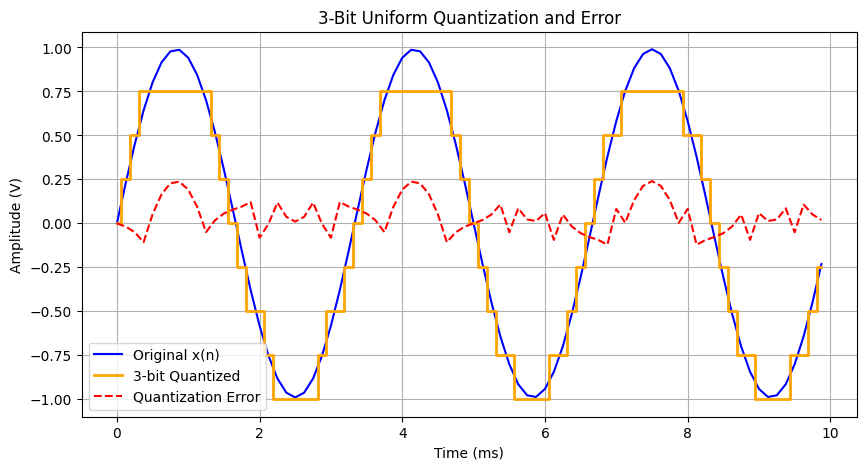

In [10]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x_sine = 0.99 * np.sin(2 * np.pi * 300 * t)
xq = quantize(x_sine, 3)

# Visualization of original signal, quantized signal, and quantization error
plt.figure(figsize=(10, 5))
plt.plot(t * 1e3, x_sine, 'b-', label="Original x(n)")
plt.step(t * 1e3, xq, where="mid", color='orange', linewidth=2, label="3-bit Quantized")
plt.plot(t * 1e3, x_sine - xq, 'r--', label="Quantization Error")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.title("3-Bit Uniform Quantization and Error")
plt.legend()
plt.show()

## Task 2.4 — Verification of the 6 dB-per-bit Rule

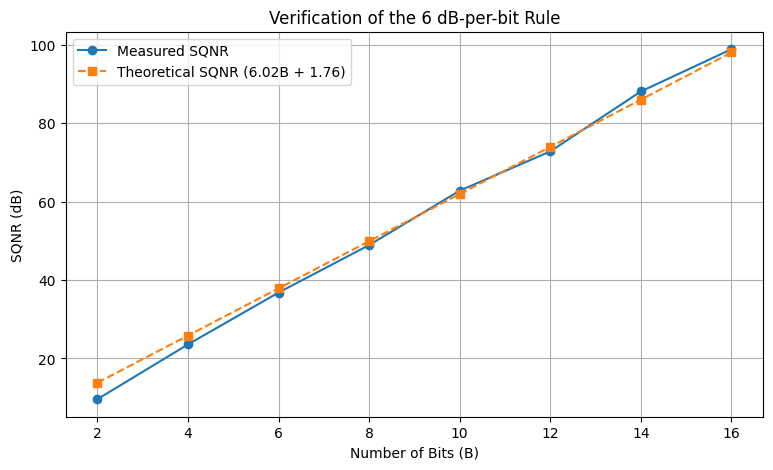

In [11]:
bits = np.arange(2, 17, 2)
meas = []

for B in bits:
    xq_temp = quantize(x_sine, B)
    error_temp = x_sine - xq_temp
    sqnr_val = 10 * np.log10(np.sum(x_sine**2) / np.sum(error_temp**2))
    meas.append(sqnr_val)

# Verification plot
plt.figure(figsize=(9, 5))
plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, 6.02 * bits + 1.76, "s--", label="Theoretical SQNR (6.02B + 1.76)")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of the 6 dB-per-bit Rule")
plt.legend()
plt.show()

## Task 2.5 — Voice Quantization Analysis

In [12]:
speech_sqnr = {}
for B in [4, 8, 12]:
    xq_speech = quantize(x, B)
    err_speech = x - xq_speech
    sqnr_val = 10 * np.log10(np.sum(x**2) / np.sum(err_speech**2))
    speech_sqnr[B] = sqnr_val

    print(f"--- {B}-bit Quantized Speech --- (SQNR: {sqnr_val:.2f} dB)")
    display(Audio(xq_speech, rate=fs))
    print("\n")

--- 4-bit Quantized Speech --- (SQNR: 20.36 dB)




--- 8-bit Quantized Speech --- (SQNR: 44.05 dB)




--- 12-bit Quantized Speech --- (SQNR: 68.01 dB)


### **SQNR Comparison: Speech vs. Sine Wave**
* **Answer:**
  The standard rule $\text{SQNR} \approx 6.02B + 1.76\text{ dB}$ is derived assuming a full-scale sinusoid which continuously utilizes the peak quantization levels.
  Speech signals are highly dynamic with a high crest factor (large peak-to-average power ratio) and contain silent intervals. Because the average signal power is much lower than the peak range, the relative quantization noise is larger, resulting in a lower practical SQNR.

## Analysis Questions

### **Question 1**
Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10\text{ Hz}$.

* **Answer:**
  Sampling replicas are located at multiples of the sampling frequency: $f = f_0 \pm k f_s$.
  For $f_0 = 7\text{ Hz}$ and $f_s = 10\text{ Hz}$:
  $$f_{\text{alias}} = |7 - 10| = 3\text{ Hz}$$
  In the frequency domain, the negative impulse at $-7\text{ Hz}$ is shifted by $+f_s = +10\text{ Hz}$ to $+3\text{ Hz}$, while the positive impulse at $+7\text{ Hz}$ shifts by $-f_s = -10\text{ Hz}$ to $-3\text{ Hz}$. Thus, a physical component at $3\text{ Hz}$ is observed.

### **Question 2**
In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?

* **Answer:**
  Once high frequencies fold back into the baseband during sampling, they overlap with original baseband components. This mixing is irreversible because there is no distinct mathematical feature separating an aliased frequency from an authentic one at the same frequency. Therefore, post-filtering cannot recover the original signal.

### **Question 3**
By how much does the SQNR change when one bit is added? Does your measurement agree?

* **Answer:**
  Each additional bit increases the SQNR by approximately **$6.02\text{ dB}$** ($20\log_{10}(2)$). This corresponds perfectly with the experimental results plotted in Task 2.4, where the SQNR increases by about $12\text{ dB}$ for every $2\text{ bits}$.

### **Question 4**
A temperature sensor changes by at most $0.1\ ^\circ\text{C}$ per second and the required resolution is $0.01\ ^\circ\text{C}$ over a range of $0\text{--}100\ ^\circ\text{C}$. Suggest a sampling rate and number of bits, and justify them.

* **Answer:**
  1. **Sampling Rate ($f_s$):**
     Since temperature variations are exceptionally slow, a conservative sampling frequency of **$1\text{ Hz}$** is highly adequate to avoid any aliasing issues.
  2. **Resolution & Bit Allocation ($B$):**
     With a range of $100\ ^\circ\text{C}$ and a resolution of $0.01\ ^\circ\text{C}$, the number of levels required is:
     $$\text{Levels} = \frac{100}{0.01} = 10,000$$
     Solving for the required number of bits:
     $$2^B \ge 10,000 \implies B \ge \log_2(10000) \approx 13.29$$
     We round up to select a standard resolution of **$14\text{ bits}$** ($16,384$ levels).